# Outbreak logistic regression + X (Twitter) sighting features

Same model as `regression_baseline.ipynb` — a **logistic regression** predicting
`target_outbreak_next_7d` from the environmental, spatial and exposure variables — plus a block of
**social-media features** built from `x_post_analysis`. The question is *incremental lift*: does
adding X sightings improve on the baseline, fitted on exactly the same rows?

Everything the baseline is careful about still applies (temporal split, ~0.3% positives judged by
PR-AUC against the base rate, negatives subsampled in training only with an analytic intercept
correction, NULL is not zero). Three new things matter here:

1. **Social features live at STATE × day, not county × day.** X posts are geocoded to a state
   reliably but rarely to a county, so every county in a state gets the same social values that day.
   The merge is on `(state, day)`.
2. **Past-only windows.** A post counts toward day *d* only if it was made on days
   *d−w … d−1* — the same `[day-w, day-1]` convention as `own_outbreaks_*`. A post made on the day
   of (or after) the outcome window would be leakage.
3. **Only `use_sightings = TRUE` posts are used** — posts that survived the whole funnel in
   `docs/x_data_funnel.md` (a local, first-hand report of sick/dead birds, one per state-week).
   That is a **very small** set (243 posts), so these features are sparse: most state-days have
   none. Read the coverage audit in section 2 before trusting any coefficient.

Requires the modeling extra and a running Cloud SQL proxy:

```bash
uv sync --extra modeling --extra dev
.\cloud-sql-proxy.exe harvard-capstone-499102:us-central1:h5n1-pg --port 5433
uv run --extra modeling --extra dev jupyter lab
```

In [1]:
# --- configuration -------------------------------------------------------------
# Same constants as regression_baseline.ipynb, plus the social-feature windows.

STUDY_START = "2022-02-08"   # first US poultry detection; earlier days are all-zero DV
SPLIT_DATE  = "2025-01-01"   # train < SPLIT_DATE <= test. TEMPORAL, never random.

NEG_SAMPLE_RATE = 0.05       # keep every training positive, sample training negatives
RANDOM_STATE    = 20260728

INCLUDE_BANDING = False      # fact_bird_density ends 2025-07-10, inside the test window

# Social features. Sightings are sparse (243 posts in 4+ years), so the sentiment /
# category / language summaries use a longer window than the post counts.
SOCIAL_COUNT_WINDOWS = [7, 21, 60]   # trailing post-count windows, days
SOCIAL_SENT_WINDOW   = 60            # window for sentiment means, category & language shares

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from h5n1.db import get_engine

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)

# --- plot style: same as regression_baseline.ipynb ---
INK, INK_2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d8d7d2", "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "600", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 9.5,
    "lines.linewidth": 2.0, "legend.frameon": False,
})

## 0. Define Variables

The target and every **non-social** feature are identical to `regression_baseline.ipynb`
(see its section 0 for definitions). The new social block, all per **state × day**, trailing
window `[day-w, day-1]`:

### Volume
- `log_x_posts_7d / _21d / _60d` — log1p count of sighting posts in the state.

### Sentiment (model scores from `x_post_sentiment`, averaged over the 60-day window)
- `x_sentiment_mean` — mean of `positive_score − negative_score`, in [−1, 1].
- `x_positive_mean`, `x_neutral_mean`, `x_negative_mean` — mean model probabilities.

### Final sentiment category (`x_post_sentiment.final_sentiment`)
- `x_share_negative`, `x_share_positive` — share of the window's posts labelled negative /
  positive. **Neutral is the reference category** — its share is `1 − negative − positive`, so
  including it too would be perfectly collinear (the classic dummy-variable trap).

### Language (`x_post_analysis.lang`)
- `x_share_english`, `x_share_french`, `x_share_spanish` — share of the window's posts in each
  language (`lang` = `en` / `fr` / `es`). A post-level category becomes a *share* once posts are
  pooled over a state-day window, the same way `final_sentiment` does. All three are kept in the
  prediction model; for inference English is the reference category (section 6), because the
  three shares sum to 1 whenever there are posts.

### No posts (NULL is not zero)
- `x_no_posts_60d` — 1 if the state had no sighting posts in the window. The means and shares
  above are *undefined* then; they are filled with 0 and this indicator carries the
  "nothing observed" information, the same trick the baseline uses for censored recency.

## 1. Load

### 1a. Non-social features — same query as the baseline

In [3]:
QUERY = f'''
SELECT fips, day, state,
       target_outbreak_next_7d,
       outbreak, own_outbreaks_7d, own_outbreaks_21d, own_outbreaks_60d,
       nbr_infected_counties_7d, nbr_infected_counties_21d, nbr_infected_counties_60d,
       nbr_infections_7d, nbr_infections_21d, nbr_infections_60d,
       nbr_wild_detections_7d, nbr_wild_detections_21d, nbr_wild_detections_60d,
       wild_detections_7d, wild_detections_21d, wild_detections_60d,
       band_count_21d, nbr_band_count_21d, has_band_coverage,
       days_since_outbreak_county, days_since_outbreak_neighbor,
       breeding_side_pressure, wintering_side_pressure,
       temp_min_7d_c, temp_max_7d_c, precip_7d_mm, precip_days_7d,
       poultry_operations, layer_operations, broiler_operations,
       turkey_operations, duck_operations, layer_inventory,
       population, pop_density_sqmi, n_neighbors, doy_sin, doy_cos
FROM feature_county_day
WHERE is_conus
  AND target_complete_7d
  AND day >= '{STUDY_START}'
  AND (
        day >= '{SPLIT_DATE}'          -- test period: complete, never sampled
     OR target_outbreak_next_7d        -- training positives: keep all
     OR random() < {NEG_SAMPLE_RATE}   -- training negatives: sample
      )
'''

df = pd.read_sql(QUERY, get_engine())
df["day"] = pd.to_datetime(df["day"])
print(f"{len(df):,} rows x {df.shape[1]} columns")
print(f"date range {df.day.min().date()} .. {df.day.max().date()}")

1,912,854 rows x 42 columns
date range 2022-02-08 .. 2026-07-14


### 1b. Social posts — `x_post_analysis` sightings, joined to the sentiment table

`final_sentiment` is not in `x_post_analysis`, so it is joined from `x_post_sentiment` on
`post_id` (unique there). `event_state` is the state the sighting is *about* — what
`h5n1.sources.x_analysis_table.sightings()` uses — rather than the author's profile state.

In [4]:
POSTS_QUERY = '''
SELECT a.post_id, a.stream, a.created_at, a.lang, a.event_state AS state,
       a.sentiment, a.positive_score, a.neutral_score, a.negative_score,
       s.final_sentiment
FROM x_post_analysis a
LEFT JOIN x_post_sentiment s USING (post_id)
WHERE a.use_sightings
'''
posts = pd.read_sql(POSTS_QUERY, get_engine())

# created_at is a UTC timestamp. Its UTC date is never EARLIER than the US local date,
# so assigning posts by UTC date can only delay a post's entry into the window -- it
# can never leak a future post into the past.
posts["day"] = pd.to_datetime(posts.created_at, utc=True).dt.tz_convert(None).dt.normalize()

assert posts.post_id.is_unique, "a post appears twice"
print(f"{len(posts)} sighting posts, {posts.state.nunique()} states, "
      f"{posts.day.min().date()} .. {posts.day.max().date()}")
display(posts.groupby("stream").agg(posts=("post_id", "size"), first=("day", "min"), last=("day", "max")))
display(posts.final_sentiment.value_counts(dropna=False).to_frame("posts"))
display(posts.lang.value_counts(dropna=False).to_frame("posts"))

243 sighting posts, 44 states, 2022-06-03 .. 2026-09-23


,posts,first,last
stream,,,
en_test,62,2025-01-02,2026-09-23
es,1,2023-01-29,2023-01-29
prior,180,2022-06-03,2024-12-30


,posts
final_sentiment,
negative,205
neutral,31
positive,7


,posts
lang,
en,242
es,1


## 2. Social features at state × day

Three steps:
1. **Daily totals per state** — post count, sums of the scores, counts per category / language.
2. **A complete state × day grid**, so a day with no posts is an explicit 0 rather than a missing
   row (otherwise a rolling window would skip over empty days).
3. **Trailing sums, shifted by one day** — `rolling(w).sum().shift(1)` covers `[day-w, day-1]`.
   Means and shares are then *sums ÷ count* over the window — averaging the daily averages would
   overweight days with a single post.

In [5]:
# 1. daily totals per state
p = posts.assign(
    n=1,
    n_neg_cat=(posts.final_sentiment == "negative").astype(int),
    n_pos_cat=(posts.final_sentiment == "positive").astype(int),
    n_en=(posts.lang == "en").astype(int),
    n_fr=(posts.lang == "fr").astype(int),
    n_es=(posts.lang == "es").astype(int),
)
SUM_COLS = ["n", "sentiment", "positive_score", "neutral_score", "negative_score",
            "n_neg_cat", "n_pos_cat", "n_en", "n_fr", "n_es"]
daily = p.groupby(["state", "day"])[SUM_COLS].sum()

# 2. complete grid: every state in the modeling data x every day of the study
days = pd.date_range(STUDY_START, df.day.max(), freq="D")
states = sorted(df.state.unique())
grid = pd.MultiIndex.from_product([states, days], names=["state", "day"])
daily = daily.reindex(grid, fill_value=0)

# 3. trailing, past-only windows, computed per state
def trailing(frame, w):
    return frame.groupby(level="state").transform(lambda s: s.rolling(w, min_periods=1).sum().shift(1)).fillna(0)

social = pd.DataFrame(index=grid)
for w in SOCIAL_COUNT_WINDOWS:
    social[f"x_posts_{w}d"] = trailing(daily[["n"]], w)["n"]

W = trailing(daily, SOCIAL_SENT_WINDOW)
n = W["n"]
has = n > 0
social["x_no_posts_60d"]      = (~has).astype(int)
social["x_sentiment_mean"]    = (W.sentiment      / n).where(has, 0.0)
social["x_positive_mean"]     = (W.positive_score / n).where(has, 0.0)
social["x_neutral_mean"]      = (W.neutral_score  / n).where(has, 0.0)
social["x_negative_mean"]     = (W.negative_score / n).where(has, 0.0)
social["x_share_negative"]    = (W.n_neg_cat      / n).where(has, 0.0)
social["x_share_positive"]    = (W.n_pos_cat      / n).where(has, 0.0)
social["x_share_english"]     = (W.n_en           / n).where(has, 0.0)
social["x_share_french"]      = (W.n_fr           / n).where(has, 0.0)
social["x_share_spanish"]     = (W.n_es           / n).where(has, 0.0)
social = social.reset_index()

SOCIAL_COLS = [c for c in social.columns if c not in ("state", "day")]
print(f"state-day grid: {len(social):,} rows; "
      f"{(social.x_no_posts_60d == 0).mean():.1%} have >=1 post in the trailing {SOCIAL_SENT_WINDOW} days")

state-day grid: 79,282 rows; 12.9% have >=1 post in the trailing 60 days


In [6]:
# --- sanity check: recompute the 7-day count straight from the posts for every day ---
# --- a post was made, the day before, and the day after, and compare ---------------
s7 = social.set_index(["state", "day"])["x_posts_7d"]
checked = 0
for st, d0 in posts[["state", "day"]].itertuples(index=False):
    for d in [d0 - pd.Timedelta(days=1), d0, d0 + pd.Timedelta(days=1)]:
        if (st, d) not in s7.index:
            continue
        expected = ((posts.state == st) & (posts.day >= d - pd.Timedelta(days=7))
                    & (posts.day <= d - pd.Timedelta(days=1))).sum()
        assert s7.loc[(st, d)] == expected, f"{st} {d.date()}: {s7.loc[(st, d)]} != {expected}"
        checked += 1
print(f"past-only window check passed on {checked} state-days "
      "(a post on day d is invisible on day d and counted from d+1)")

past-only window check passed on 717 state-days (a post on day d is invisible on day d and counted from d+1)


In [7]:
# --- merge onto the county-day rows by (state, day) -----------------------------
n_before = len(df)
df = df.merge(social, on=["state", "day"], how="left", validate="many_to_one")
assert len(df) == n_before, "merge changed the row count"
assert df[SOCIAL_COLS].notna().all().all(), "a county-day found no state-day row"

# --- coverage audit: how much signal is there, and is it the same on both sides of the split?
is_train = df.day < SPLIT_DATE
cov = pd.DataFrame({
    "rows":                     [is_train.sum(), (~is_train).sum()],
    "rows with posts (60d)":    [(df.loc[is_train, "x_no_posts_60d"] == 0).mean(),
                                 (df.loc[~is_train, "x_no_posts_60d"] == 0).mean()],
    "positives with posts (60d)": [
        (df.loc[is_train & (df.target_outbreak_next_7d), "x_no_posts_60d"] == 0).mean(),
        (df.loc[~is_train & (df.target_outbreak_next_7d), "x_no_posts_60d"] == 0).mean()],
}, index=["train", "test"])
display(cov.style.format({"rows": "{:,}", "rows with posts (60d)": "{:.2%}",
                          "positives with posts (60d)": "{:.2%}"}))
print("Training posts come from the 'prior' collection, test posts from 'en_test' -- a different")
print("collector. A change in coverage between the two rows above is partly a data-collection")
print("shift, not epidemiology.")

,rows,rows with posts (60d),positives with posts (60d)
train,"172,374",15.40%,20.38%
test,"1,740,480",12.29%,22.56%


Training posts come from the 'prior' collection, test posts from 'en_test' -- a different
collector. A change in coverage between the two rows above is partly a data-collection
shift, not epidemiology.


## 3. Feature preparation

`build_X` is the baseline's feature preparation, unchanged. `add_social` appends the social block:
post counts get `log1p` (same reason as every other count), and the means/shares are already on
a 0–1 (or −1–1) scale so they pass through.

In [8]:
COUNT_COLS = [
    "own_outbreaks_7d", "own_outbreaks_21d", "own_outbreaks_60d",
    "nbr_infected_counties_7d", "nbr_infected_counties_21d", "nbr_infected_counties_60d",
    "nbr_infections_7d", "nbr_infections_21d", "nbr_infections_60d",
    "nbr_wild_detections_7d", "nbr_wild_detections_21d", "nbr_wild_detections_60d",
    "wild_detections_7d", "wild_detections_21d", "wild_detections_60d",
    "breeding_side_pressure", "wintering_side_pressure",
    "poultry_operations", "layer_operations", "broiler_operations",
    "turkey_operations", "duck_operations", "population",
]
PASSTHROUGH = ["temp_min_7d_c", "temp_max_7d_c", "precip_7d_mm",
               "doy_sin", "doy_cos", "n_neighbors"]


def build_X(frame):
    # identical to regression_baseline.ipynb
    Xv = pd.DataFrame(index=frame.index)

    for c in COUNT_COLS:
        Xv[f"log_{c}"] = np.log1p(frame[c].clip(lower=0))

    for c in ["days_since_outbreak_county", "days_since_outbreak_neighbor"]:
        Xv[f"{c}_censored"] = frame[c].isna().astype(int)
        Xv[c] = frame[c].fillna(400) / 100.0

    Xv["layer_inventory_suppressed"] = (frame.layer_inventory.isna() & (frame.layer_operations > 0)).astype(int)
    Xv["log_layer_inventory"] = np.log1p(frame.layer_inventory.fillna(frame.layer_inventory.median()))

    if INCLUDE_BANDING:
        Xv["log_band_count_21d"] = np.log1p(frame.band_count_21d.clip(lower=0))
        Xv["log_nbr_band_count_21d"] = np.log1p(frame.nbr_band_count_21d.clip(lower=0))

    for c in PASSTHROUGH:
        Xv[c] = frame[c]

    Xv["weather_missing"] = frame.temp_max_7d_c.isna().astype(int)
    for c in ["temp_min_7d_c", "temp_max_7d_c", "precip_7d_mm"]:
        Xv[c] = Xv[c].fillna(Xv.loc[frame.day < SPLIT_DATE, c].median())

    return Xv


SOCIAL_PASSTHROUGH = ["x_no_posts_60d", "x_sentiment_mean",
                      "x_positive_mean", "x_neutral_mean", "x_negative_mean",
                      "x_share_negative", "x_share_positive",
                      "x_share_english", "x_share_french", "x_share_spanish"]


def add_social(Xv, frame):
    Xv = Xv.copy()
    for w in SOCIAL_COUNT_WINDOWS:
        Xv[f"log_x_posts_{w}d"] = np.log1p(frame[f"x_posts_{w}d"])
    for c in SOCIAL_PASSTHROUGH:
        Xv[c] = frame[c]
    return Xv


X_base = build_X(df)
X_soc = add_social(X_base, df)
y = df.target_outbreak_next_7d.astype(int)
print(f"baseline design matrix: {X_base.shape[0]:,} x {X_base.shape[1]}")
print(f"social   design matrix: {X_soc.shape[0]:,} x {X_soc.shape[1]}   "
      f"(+{X_soc.shape[1] - X_base.shape[1]} social columns)")

baseline design matrix: 1,912,854 x 36
social   design matrix: 1,912,854 x 49   (+13 social columns)


In [9]:
# --- leakage assertion: no target_* or same-day outbreak column may reach the model ---
for name, Xv in [("baseline", X_base), ("social", X_soc)]:
    banned = [c for c in Xv.columns if c.startswith("target_") or c == "outbreak"]
    assert not banned, f"LEAKAGE in {name}: {banned}"
    assert Xv.isna().sum().sum() == 0, f"NaNs in {name} design matrix"
print("leakage check passed -- social windows are past-only ([day-w, day-1], checked in section 2)")

leakage check passed -- social windows are past-only ([day-w, day-1], checked in section 2)


## 4. Temporal split and fit — baseline vs. baseline + social, same rows

Both models are fitted on **identical** rows (the same random negative sample), so any
difference is due to the social columns, not to sampling noise between notebook runs.

`LogisticRegression` uses L2 regularization (`C=1.0`) by default. That matters here: several
social columns are exact linear combinations of each other (`x_sentiment_mean` =
`x_positive_mean − x_negative_mean`, and the three probability means sum to 1 whenever there are
posts). The L2 penalty keeps the fit well-defined anyway — it shares the weight across the
collinear columns — so the *predictions* are fine, but the individual coefficients on those
columns are not separately interpretable. Section 6 deals with that for inference.

In [10]:
train, test = df.day < SPLIT_DATE, df.day >= SPLIT_DATE


def fit_and_score(Xv, label):
    m = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE))
    m.fit(Xv[train], y[train])
    # prior correction for case-control sampling: slopes unbiased, intercept offset by log(rate)
    m.named_steps["logisticregression"].intercept_ += np.log(NEG_SAMPLE_RATE)
    p = m.predict_proba(Xv[test])[:, 1]
    y_te = y[test]
    return m, p, {
        "model": label,
        "n_features": Xv.shape[1],
        "ROC-AUC": roc_auc_score(y_te, p),
        "PR-AUC": average_precision_score(y_te, p),
        "PR-AUC lift vs base": average_precision_score(y_te, p) / y_te.mean(),
        "Brier": brier_score_loss(y_te, p),
    }


model_base, p_base, s_base = fit_and_score(X_base, "baseline")
model_soc,  p_soc,  s_soc  = fit_and_score(X_soc,  "baseline + X social")

y_te = y[test]
base_rate = y_te.mean()
results = pd.DataFrame([s_base, s_soc]).set_index("model")
results.loc["difference"] = results.loc["baseline + X social"] - results.loc["baseline"]
print(f"test rows {len(y_te):,} | test positives {int(y_te.sum()):,} | base rate {base_rate:.4%}\n")
display(results.style.format({"n_features": "{:.0f}", "ROC-AUC": "{:+.4f}", "PR-AUC": "{:+.4f}",
                              "PR-AUC lift vs base": "{:+.2f}", "Brier": "{:+.6f}"}))
print("Read PR-AUC against the base rate. A difference in the 3rd decimal place on one test")
print("period is not evidence of lift on its own -- see section 7.")

test rows 1,740,480 | test positives 4,366 | base rate 0.2509%



,n_features,ROC-AUC,PR-AUC,PR-AUC lift vs base,Brier
model,,,,,
baseline,36,+0.8765,+0.1176,+46.88,+0.002527
baseline + X social,49,+0.8764,+0.1162,+46.31,+0.002533
difference,13,-0.0001,-0.0014,-0.57,+0.000006


Read PR-AUC against the base rate. A difference in the 3rd decimal place on one test
period is not evidence of lift on its own -- see section 7.


## 5. Diagnostics

findfont: Failed to find font weight 600, now using 700.


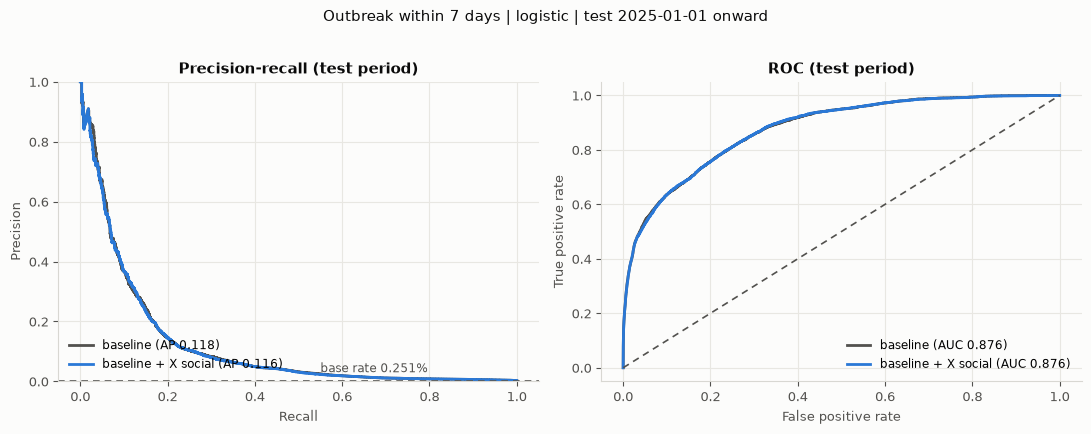

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for p, color, label in [(p_base, INK_2, "baseline"), (p_soc, BLUE, "baseline + X social")]:
    prec, rec, _ = precision_recall_curve(y_te, p)
    axes[0].plot(rec, prec, color=color, label=f"{label} (AP {average_precision_score(y_te, p):.3f})")
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[1].plot(fpr, tpr, color=color, label=f"{label} (AUC {roc_auc_score(y_te, p):.3f})")

axes[0].axhline(base_rate, color=INK_2, lw=1.2, ls=(0, (4, 3)))
axes[0].annotate(f"base rate {base_rate:.3%}", (0.55, base_rate), textcoords="offset points",
                 xytext=(0, 6), color=INK_2, fontsize=8.5)
axes[0].set(xlabel="Recall", ylabel="Precision", ylim=(0, 1), title="Precision-recall (test period)")
axes[1].plot([0, 1], [0, 1], color=INK_2, lw=1.2, ls=(0, (4, 3)))
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (test period)")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[0] else "lower right", fontsize=8.5)

fig.suptitle(f"Outbreak within 7 days | logistic | test {SPLIT_DATE} onward",
             fontsize=10.5, color=INK, y=1.02)
fig.tight_layout()
plt.show()

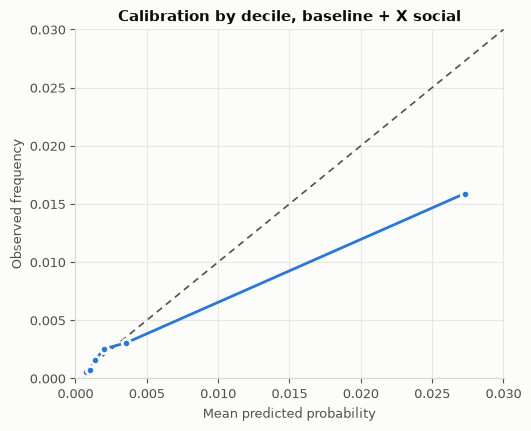

In [12]:
# --- calibration of the social model: decile bins of predicted probability vs observed ---
cal = pd.DataFrame({"p": p_soc, "y": y_te.values})
cal["bin"] = pd.qcut(cal.p, 10, labels=False, duplicates="drop")
g = cal.groupby("bin").agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))

fig, ax = plt.subplots(figsize=(5.4, 4.4))
lim = max(g.pred.max(), g.obs.max()) * 1.1
ax.plot([0, lim], [0, lim], color=INK_2, lw=1.2, ls=(0, (4, 3)))
ax.plot(g.pred, g.obs, color=BLUE, marker="o", markersize=6,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.set(xlabel="Mean predicted probability", ylabel="Observed frequency",
       title="Calibration by decile, baseline + X social", xlim=(0, lim), ylim=(0, lim))
fig.tight_layout()
plt.show()

## 6. Inference — coefficients with **state**-clustered standard errors

Same approach as the baseline (refit with `statsmodels` on the training window), with two changes:

- **Cluster by state, not county.** The social features take one value per state-day, so every
  county in a state shares the same social "observation". Clustering by county would treat those
  as independent and make the social standard errors far too small. State clustering
  (~48 clusters) is the conservative choice; it widens every interval, baseline features included.
- **Drop the exactly-redundant social columns.** Unregularized logistic regression can't separate
  perfectly collinear columns — the standard errors are undefined. `x_sentiment_mean` is
  `x_positive_mean − x_negative_mean`, and `x_neutral_mean` is `1 − positive − negative` when there
  are posts, so both are dropped *here only*. Their information is still in the model through
  `x_positive_mean` and `x_negative_mean`. Likewise `x_share_english` = `1 − french − spanish`,
  so English is dropped and becomes the **reference language**: the French and Spanish odds
  ratios read as "a higher share of posts in this language, relative to English".
- Columns that are constant in the training window (zero variance) are dropped too — currently
  `x_share_french`, since no French post survives to the sightings stage.

In [13]:
REDUNDANT = ["x_sentiment_mean", "x_neutral_mean", "x_share_english"]
X_inf = X_soc.loc[train].drop(columns=REDUNDANT)
const_cols = X_inf.columns[X_inf.std() == 0].tolist()
if const_cols:
    print(f"dropping constant-in-training columns: {const_cols}")
X_inf = X_inf.drop(columns=const_cols)

Xs = (X_inf - X_inf.mean()) / X_inf.std()   # standardized -> comparable ORs
Xs = sm.add_constant(Xs, has_constant="add")

res = sm.Logit(y[train].values, Xs).fit(
    disp=False, method="lbfgs", maxiter=500,
    cov_type="cluster", cov_kwds={"groups": df.loc[train, "state"].values},
)

ci = np.asarray(res.conf_int())
coef = pd.DataFrame({
    "odds_ratio": np.exp(np.asarray(res.params)),
    "ci_low":     np.exp(ci[:, 0]),
    "ci_high":    np.exp(ci[:, 1]),
    "p_value":    np.asarray(res.pvalues),
}, index=Xs.columns).drop("const")
coef["significant"] = coef.p_value < 0.05
coef["social"] = coef.index.str.match(r"(log_)?x_")

print("Odds ratio per 1 SD increase. Clustered by state "
      f"(n_clusters = {df.loc[train, 'state'].nunique()}).\n")
print("Social features:")
display(coef[coef.social].drop(columns="social").style.format(
    {"odds_ratio": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "p_value": "{:.2e}"}))
print("All features, by odds ratio:")
display(coef.sort_values("odds_ratio", ascending=False).drop(columns="social").style.format(
    {"odds_ratio": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "p_value": "{:.2e}"}))

dropping constant-in-training columns: ['x_share_french']
Odds ratio per 1 SD increase. Clustered by state (n_clusters = 49).

Social features:


,odds_ratio,ci_low,ci_high,p_value,significant
log_x_posts_7d,1.018,0.954,1.087,5.93e-01,False
log_x_posts_21d,0.948,0.864,1.041,2.61e-01,False
log_x_posts_60d,1.286,1.105,1.497,1.18e-03,True
x_no_posts_60d,0.734,0.325,1.658,4.58e-01,False
x_positive_mean,0.643,0.302,1.368,2.52e-01,False
x_negative_mean,1.035,0.387,2.767,9.45e-01,False
x_share_negative,0.627,0.388,1.015,5.75e-02,False
x_share_positive,1.212,0.775,1.897,3.99e-01,False
x_share_spanish,0.992,0.979,1.006,2.44e-01,False


All features, by odds ratio:


,odds_ratio,ci_low,ci_high,p_value,significant
log_poultry_operations,1.601,0.999,2.564,5.02e-02,False
log_turkey_operations,1.408,1.218,1.626,3.56e-06,True
log_population,1.313,1.103,1.564,2.25e-03,True
log_breeding_side_pressure,1.286,1.205,1.373,3.57e-14,True
log_x_posts_60d,1.286,1.105,1.497,1.18e-03,True
log_wintering_side_pressure,1.245,1.159,1.337,1.87e-09,True
x_share_positive,1.212,0.775,1.897,3.99e-01,False
log_own_outbreaks_7d,1.177,1.133,1.223,4.33e-17,True
log_layer_inventory,1.167,1.069,1.274,5.58e-04,True
log_own_outbreaks_21d,1.138,1.074,1.206,1.13e-05,True


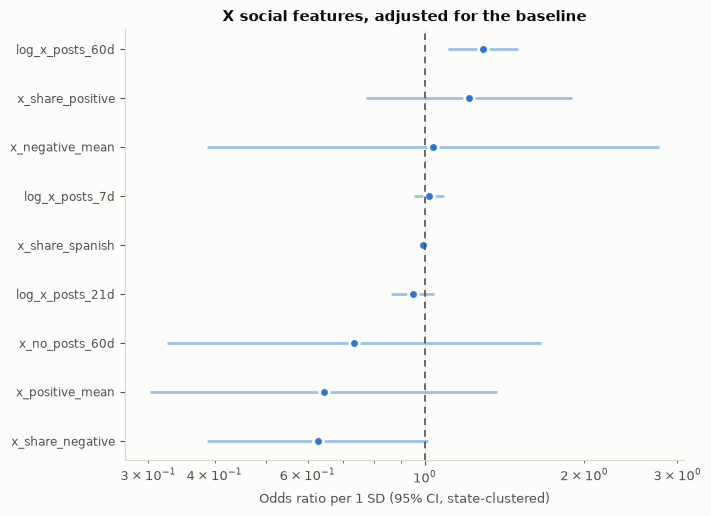

In [14]:
# --- forest plot of the social coefficients (log scale; 1.0 = no effect) ---
sc = coef[coef.social].sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(7.2, 0.45 * len(sc) + 1.2))
ypos = np.arange(len(sc))
ax.hlines(ypos, sc.ci_low, sc.ci_high, color=BLUE, lw=2, alpha=0.45)
ax.plot(sc.odds_ratio, ypos, "o", color=BLUE, markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2, linestyle="none")
ax.axvline(1.0, color=INK_2, lw=1.2, ls=(0, (4, 3)))
ax.set_yticks(ypos)
ax.set_yticklabels(sc.index, fontsize=8.5)
ax.set_xscale("log")
ax.set(xlabel="Odds ratio per 1 SD (95% CI, state-clustered)",
       title="X social features, adjusted for the baseline")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 7. Tree models — decision tree and random forest

Same two models as `regression_baseline.ipynb` section 10, with the same settings, each fitted
**with and without** the social block on the same rows:

- **Decision tree** — `max_depth=6, min_samples_leaf=200` (shallow, interpretable, untuned).
- **Random forest** — `n_estimators=300, max_depth=6, min_samples_leaf=2`, the production
  settings from the baseline's hyperparameter sweep.

Two differences from the logistic model:

- **Sample weights instead of an intercept correction.** A tree has no intercept to shift, so
  each sampled training negative gets weight `1 / NEG_SAMPLE_RATE` (it stands in for the ~20
  negatives that weren't sampled). Splits and leaf probabilities are then fitted against the true
  population balance, and the predicted probabilities are comparable to the logistic model's.
- **Collinearity doesn't matter for prediction.** A tree picks one column per split, so the
  redundant social columns (`x_sentiment_mean` vs. positive − negative, the language shares) can
  all stay in. The cost is in *importance*: correlated columns split the credit between them.

`log_layer_operations` is dropped as in the baseline (collinear with `log_poultry_operations`).

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

TREE_DROP_COLS = ["log_layer_operations"]
X_base_tree = X_base.drop(columns=TREE_DROP_COLS)
X_soc_tree = X_soc.drop(columns=TREE_DROP_COLS)

# inverse-probability weights: undo the case-control sampling of training negatives
sample_weight_tr = np.where(y[train].values == 1, 1.0, 1.0 / NEG_SAMPLE_RATE)

TREE_MODELS = {
    "tree":   lambda: DecisionTreeClassifier(max_depth=6, min_samples_leaf=200,
                                             random_state=RANDOM_STATE),
    "forest": lambda: RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2,
                                             random_state=RANDOM_STATE, n_jobs=-1),
}


def fit_and_score_tree(kind, Xv, label):
    m = TREE_MODELS[kind]()
    m.fit(Xv[train], y[train], sample_weight=sample_weight_tr)
    p = m.predict_proba(Xv[test])[:, 1]
    return m, p, {
        "model": label,
        "n_features": Xv.shape[1],
        "ROC-AUC": roc_auc_score(y_te, p),
        "PR-AUC": average_precision_score(y_te, p),
        "PR-AUC lift vs base": average_precision_score(y_te, p) / base_rate,
        "Brier": brier_score_loss(y_te, p),
        "mean predicted prob": p.mean(),
    }


fitted, preds, rows = {}, {}, []
for kind in TREE_MODELS:
    for block, Xv in [("baseline", X_base_tree), ("baseline + X social", X_soc_tree)]:
        label = f"{kind}: {block}"
        fitted[label], preds[label], s = fit_and_score_tree(kind, Xv, label)
        rows.append(s)
        print(f"fitted {label}")

fitted tree: baseline
fitted tree: baseline + X social
fitted forest: baseline
fitted forest: baseline + X social


In [16]:
# --- every model, side by side: does the social block help any of them? -------------
preds["logistic: baseline"] = p_base
preds["logistic: baseline + X social"] = p_soc
logistic_rows = [{**s_base, "model": "logistic: baseline", "mean predicted prob": p_base.mean()},
                 {**s_soc, "model": "logistic: baseline + X social", "mean predicted prob": p_soc.mean()}]

all_results = pd.DataFrame(logistic_rows + rows).set_index("model")
display(all_results.style.format({"n_features": "{:.0f}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}",
                                  "PR-AUC lift vs base": "{:.1f}x", "Brier": "{:.6f}",
                                  "mean predicted prob": "{:.4%}"}))

lift = pd.DataFrame({
    kind: {m: all_results.loc[f"{kind}: baseline + X social", m] - all_results.loc[f"{kind}: baseline", m]
           for m in ["ROC-AUC", "PR-AUC"]}
    for kind in ["logistic", "tree", "forest"]
}).T
print(f"Social-block lift (with minus without), test base rate {base_rate:.4%}:")
display(lift.style.format("{:+.4f}"))
print("mean predicted prob should sit near the base rate for every row -- that is what the")
print("intercept correction (logistic) and the sample weights (trees) are for.")

,n_features,ROC-AUC,PR-AUC,PR-AUC lift vs base,Brier,mean predicted prob
model,,,,,,
logistic: baseline,36,0.8765,0.1176,46.9x,0.002527,0.3722%
logistic: baseline + X social,49,0.8764,0.1162,46.3x,0.002533,0.3745%
tree: baseline,35,0.8251,0.0972,38.7x,0.002351,0.2866%
tree: baseline + X social,48,0.8251,0.0972,38.7x,0.002351,0.2866%
forest: baseline,35,0.8787,0.1431,57.0x,0.002300,0.2938%
forest: baseline + X social,48,0.8802,0.1424,56.8x,0.002301,0.2903%


Social-block lift (with minus without), test base rate 0.2509%:


,ROC-AUC,PR-AUC
logistic,-0.0001,-0.0014
tree,+0.0000,+0.0000
forest,+0.0015,-0.0007


mean predicted prob should sit near the base rate for every row -- that is what the
intercept correction (logistic) and the sample weights (trees) are for.


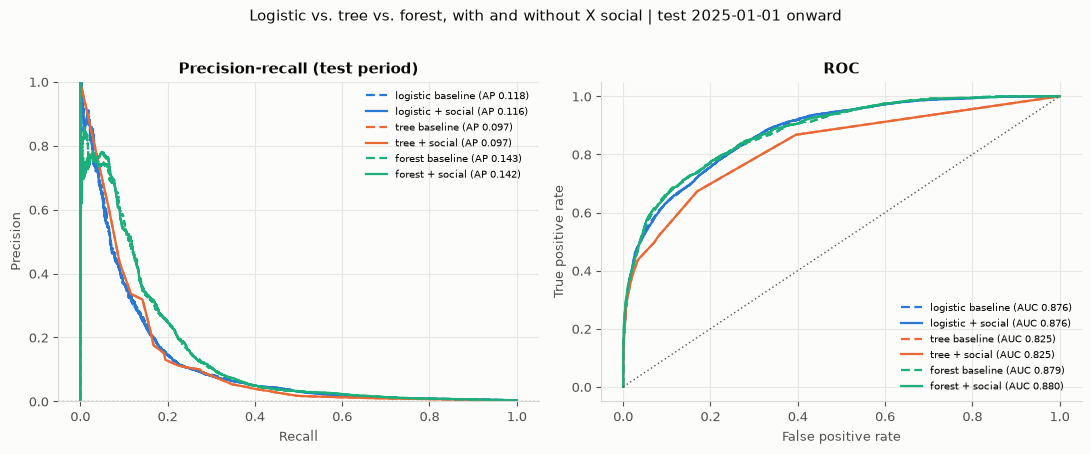

In [17]:
# --- PR / ROC: each model family with (solid) and without (dashed) the social block ---
COLORS = {"logistic": BLUE, "tree": ORANGE, "forest": AQUA}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

for kind, color in COLORS.items():
    for block, ls in [("baseline", (0, (4, 2))), ("baseline + X social", "-")]:
        p = preds[f"{kind}: {block}"]
        short = "+ social" if block != "baseline" else "baseline"
        prec, rec, _ = precision_recall_curve(y_te, p)
        axes[0].plot(rec, prec, color=color, ls=ls, lw=1.6,
                     label=f"{kind} {short} (AP {average_precision_score(y_te, p):.3f})")
        fpr, tpr, _ = roc_curve(y_te, p)
        axes[1].plot(fpr, tpr, color=color, ls=ls, lw=1.6,
                     label=f"{kind} {short} (AUC {roc_auc_score(y_te, p):.3f})")

axes[0].axhline(base_rate, color=INK_2, lw=1.0, ls=(0, (1, 2)))
axes[0].set(xlabel="Recall", ylabel="Precision", ylim=(0, 1), title="Precision-recall (test period)")
axes[1].plot([0, 1], [0, 1], color=INK_2, lw=1.0, ls=(0, (1, 2)))
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
axes[0].legend(loc="upper right", fontsize=7.5)
axes[1].legend(loc="lower right", fontsize=7.5)

fig.suptitle(f"Logistic vs. tree vs. forest, with and without X social | test {SPLIT_DATE} onward",
             fontsize=10.5, color=INK, y=1.02)
fig.tight_layout()
plt.show()

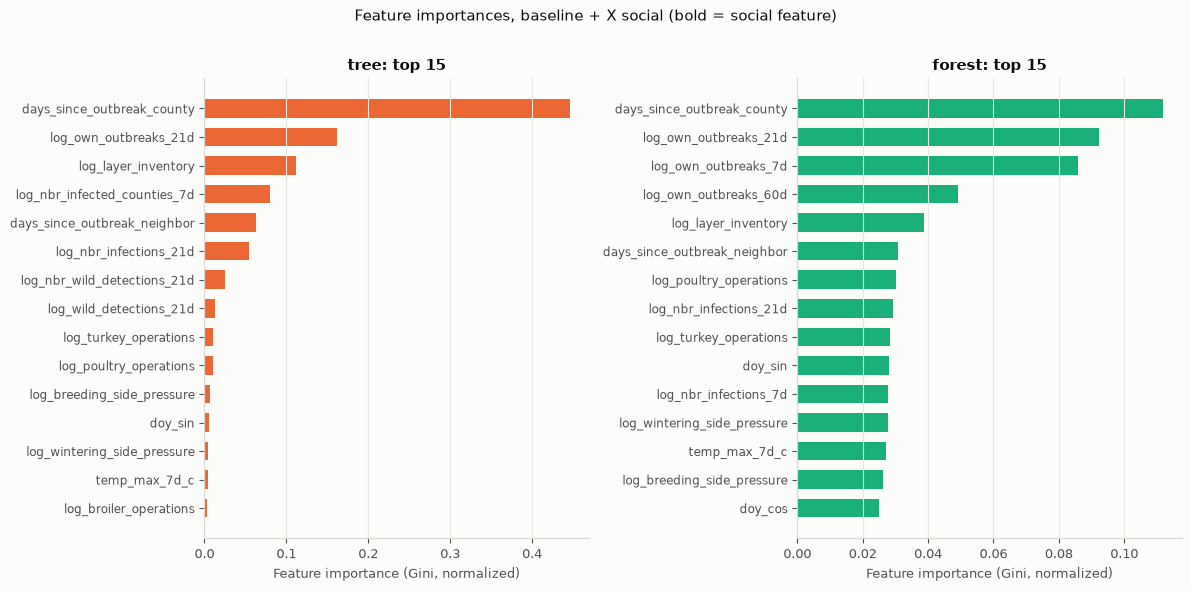

Importance of every social column (share of the model's total splitting power):


,tree,forest
log_x_posts_60d,0.0000,0.0105
x_positive_mean,0.0000,0.0085
log_x_posts_21d,0.0000,0.0074
x_neutral_mean,0.0000,0.0068
x_sentiment_mean,0.0000,0.0050
x_negative_mean,0.0000,0.0046
log_x_posts_7d,0.0000,0.0040
x_share_negative,0.0000,0.0018
x_share_english,0.0000,0.0012
x_no_posts_60d,0.0000,0.0011


In [18]:
# --- feature importances of the social models (bold = social feature) ----------------
# feature_importances_ is the normalized total Gini reduction a column is responsible for
# (averaged over trees for the forest). No sign, not per unit. Gini importance favours
# continuous columns with many split points, so a sparse 0/1-ish social column is
# disadvantaged -- read a small value as "rarely useful", not "proven useless".
is_social = lambda idx: idx.str.match(r"(log_)?x_")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
for ax, kind, color in [(axes[0], "tree", ORANGE), (axes[1], "forest", AQUA)]:
    m = fitted[f"{kind}: baseline + X social"]
    imp = pd.Series(m.feature_importances_, index=X_soc_tree.columns).sort_values(ascending=False)
    top = imp.head(15)
    ypos = np.arange(len(top))
    ax.barh(ypos, top.values, color=color, height=0.65)
    ax.set_yticks(ypos)
    for lab, soc in zip(ax.set_yticklabels(top.index, fontsize=8.5), is_social(top.index)):
        if soc:
            lab.set_fontweight("bold")
            lab.set_color(INK)
    ax.invert_yaxis()
    ax.set(xlabel="Feature importance (Gini, normalized)", title=f"{kind}: top 15")
    ax.grid(axis="y", visible=False)
fig.suptitle("Feature importances, baseline + X social (bold = social feature)",
             fontsize=10.5, color=INK, y=1.01)
fig.tight_layout()
plt.show()

soc_imp = pd.DataFrame({
    kind: pd.Series(fitted[f"{kind}: baseline + X social"].feature_importances_, index=X_soc_tree.columns)
    for kind in TREE_MODELS
})
soc_imp = soc_imp[is_social(soc_imp.index)].sort_values("forest", ascending=False)
soc_imp.loc["TOTAL (social block)"] = soc_imp.sum()
print("Importance of every social column (share of the model's total splitting power):")
display(soc_imp.style.format("{:.4f}"))

## 8. What this is and is not

**Is:** the baseline model with a past-only, state-level X sighting block added, compared against
the baseline on identical rows with population-valid test metrics.

**Is not** (yet) evidence that X adds early warning. Things to keep in mind, roughly in order:

1. **Very sparse signal.** 243 sighting posts over ~4 years; most state-days have none, so the
   social block is mostly the `x_no_posts_60d` indicator. Expect small, noisy differences.
2. **Different collectors on each side of the split.** Training-period posts are the `prior`
   stream, test-period posts are `en_test`. A coefficient learned on one may not transfer.
3. **Language is nearly constant.** 242 of 243 sighting posts are English, one is Spanish and
   none is French, so the language shares carry almost no information (`x_share_french` is all
   zeros). They are kept because they were requested, and would matter more if the funnel were
   widened (e.g. `use_sentiment` instead of `use_sightings`, which keeps far more posts).
4. **State resolution.** A sighting in one corner of Texas raises every Texas county equally.
5. **Sightings may *follow* outbreaks rather than precede them.** A post reacting to a
   just-announced detection is real, past-only information, but it isn't early warning. An event
   study (`h5n1/models/x_event_study.py`) or controlling for `own_outbreaks_*` / state outbreak
   counts addresses that more directly than a coefficient here.
6. **One test period, one seed, no uncertainty on the lift.** A bootstrap over states (or a
   permutation of the social block) would say whether the PR-AUC difference is distinguishable
   from noise. For the forest, `h5n1/models/x_lift.py` already does this with several seeds and a
   bootstrap, using the same forest settings — the right tool for a claim beyond this notebook.